<a href="https://colab.research.google.com/github/gusdn6280-crypto/bigdata_hackathon/blob/main/5756470(%EC%9D%B4%ED%98%84%EC%9A%B0).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q sympy==1.13.3

import os
import zipfile
import gdown
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# ==========================================================
# 1. Google Drive 공유 URL(파일 ID)을 이용한 데이터셋 자동 다운로드
# ==========================================================
FILE_ID = "1TnN1s5xiyXSZkxMnYw9Ura4SQvUiUE6F"
zip_path = "/content/archive.zip"
extract_path = "/content/dataset"

if not os.path.exists(extract_path):
    if not os.path.exists(zip_path):
        print("Google Drive 공유 링크로부터 데이터셋 다운로드 중...")
        url = f"https://drive.google.com/uc?id={FILE_ID}"
        gdown.download(url, zip_path, quiet=False)

    os.makedirs(extract_path, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(f"압축 해제 완료: {zip_path} -> {extract_path}")
else:
    print("이미 압축이 해제되어 있습니다.")

# ==========================================================
# 2. 클래스 폴더 경로 자동 탐색 및 공통 Dataset Wrapper 정의
# ==========================================================
data_dir = next(root for root, dirs, files in os.walk(extract_path) if len(dirs) >= 10)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

full_dataset = datasets.ImageFolder(root=data_dir)
num_classes = len(full_dataset.classes)

class TransformDataset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        return self.transform(x) if self.transform else x, y

    def __len__(self):
        return len(self.subset)

print(f"데이터 경로: {data_dir} | 연산 장치: {device} | 총 클래스: {num_classes}개")

이미 압축이 해제되어 있습니다.
데이터 경로: /content/dataset/garbage_classification | 연산 장치: cuda | 총 클래스: 12개


In [ ]:
# ==========================================
# Exp 1: Baseline (과적합 비교 대조군)
# ==========================================
torch.manual_seed(42)

base_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_data, val_data = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(TransformDataset(train_data, base_transform), batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(TransformDataset(val_data, base_transform), batch_size=32, shuffle=False, num_workers=2)

model_exp1 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_exp1.fc = nn.Linear(model_exp1.fc.in_features, num_classes)
model_exp1 = model_exp1.to(device)

criterion_exp1 = nn.CrossEntropyLoss()
optimizer_exp1 = optim.AdamW(model_exp1.parameters(), lr=1e-4, weight_decay=0.0)

history_exp1 = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_acc_exp1 = 0.0

for epoch in range(15):
    model_exp1.train()
    tr_loss, tr_corr, tr_tot = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer_exp1.zero_grad()
        outputs = model_exp1(images)
        loss = criterion_exp1(outputs, labels)
        loss.backward()
        optimizer_exp1.step()
        tr_loss += loss.item() * images.size(0)
        tr_tot += labels.size(0)
        tr_corr += (outputs.argmax(1) == labels).sum().item()

    model_exp1.eval()
    va_loss, va_corr, va_tot = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_exp1(images)
            loss = criterion_exp1(outputs, labels)
            va_loss += loss.item() * images.size(0)
            va_tot += labels.size(0)
            va_corr += (outputs.argmax(1) == labels).sum().item()

    ep_tr_loss, ep_tr_acc = tr_loss / tr_tot, tr_corr / tr_tot
    ep_va_loss, ep_va_acc = va_loss / va_tot, va_corr / va_tot

    history_exp1["train_loss"].append(ep_tr_loss)
    history_exp1["val_loss"].append(ep_va_loss)
    history_exp1["train_acc"].append(ep_tr_acc)
    history_exp1["val_acc"].append(ep_va_acc)

    print(f"[Exp 1] Epoch [{epoch+1:02d}/15] Train Loss: {ep_tr_loss:.4f}, Acc: {ep_tr_acc:.4f} | Val Loss: {ep_va_loss:.4f}, Acc: {ep_va_acc:.4f}")
    if ep_va_acc > best_acc_exp1:
        best_acc_exp1 = ep_va_acc
        torch.save(model_exp1.state_dict(), "best_model_exp1.pth")

print(f"\n[Exp 1: Baseline] 최고 검증 정확도: {best_acc_exp1:.4f}")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_exp1["train_loss"], label="Train Loss", marker='o')
plt.plot(history_exp1["val_loss"], label="Val Loss", marker='s')
plt.title("Exp 1 (Baseline) Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_exp1["train_acc"], label="Train Accuracy", marker='o')
plt.plot(history_exp1["val_acc"], label="Val Accuracy", marker='s')
plt.title("Exp 1 (Baseline) Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("learning_curve_exp1.png", dpi=300)
plt.show()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 168MB/s]


[Exp 1] Epoch [01/15] Train Loss: 0.3407, Acc: 0.8994 | Val Loss: 0.1388, Acc: 0.9520


[Exp 2] Epoch [01/15] Train Loss: 0.5068, Acc: 0.8427 | Val Loss: 0.1865, Acc: 0.9452
[Exp 2] Epoch [02/15] Train Loss: 0.2082, Acc: 0.9326 | Val Loss: 0.1526, Acc: 0.9562
[Exp 2] Epoch [03/15] Train Loss: 0.1536, Acc: 0.9537 | Val Loss: 0.1505, Acc: 0.9578
[Exp 2] Epoch [04/15] Train Loss: 0.1067, Acc: 0.9654 | Val Loss: 0.1215, Acc: 0.9668
[Exp 2] Epoch [05/15] Train Loss: 0.0889, Acc: 0.9732 | Val Loss: 0.1404, Acc: 0.9581
[Exp 2] Epoch [06/15] Train Loss: 0.0710, Acc: 0.9787 | Val Loss: 0.1045, Acc: 0.9678
[Exp 2] Epoch [07/15] Train Loss: 0.0714, Acc: 0.9775 | Val Loss: 0.1289, Acc: 0.9597
[Exp 2] Epoch [08/15] Train Loss: 0.0584, Acc: 0.9826 | Val Loss: 0.1333, Acc: 0.9633
[Exp 2] Epoch [09/15] Train Loss: 0.0444, Acc: 0.9859 | Val Loss: 0.1438, Acc: 0.9629
[Exp 2] Epoch [10/15] Train Loss: 0.0271, Acc: 0.9920 | Val Loss: 0.1028, Acc: 0.9729
[Exp 2] Epoch [11/15] Train Loss: 0.0214, Acc: 0.9941 | Val Loss: 0.1014, Acc: 0.9762
[Exp 2] Epoch [12/15] Train Loss: 0.0152, Acc: 0.9959 

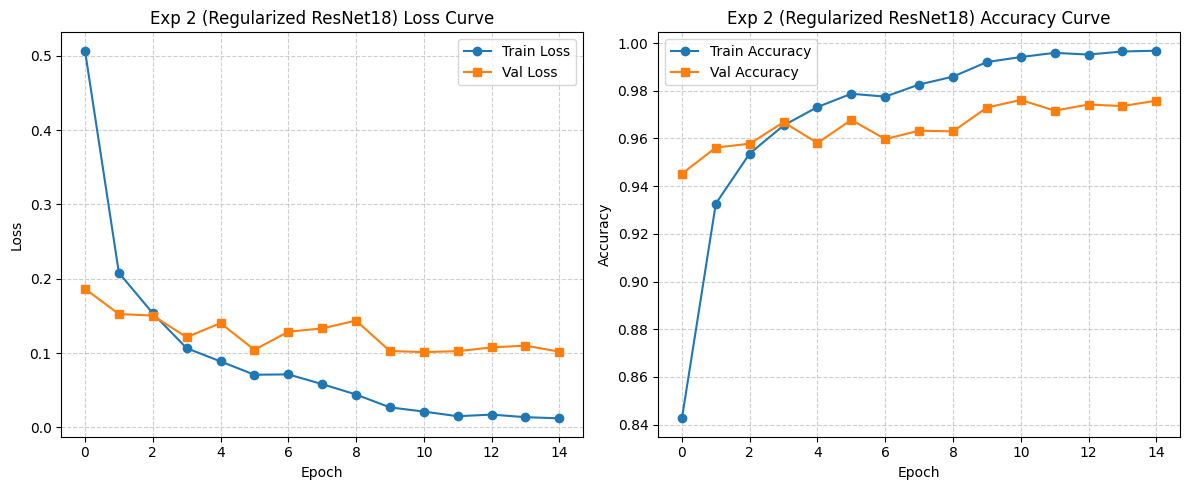

In [ ]:
# ==========================================
# Exp 2: Regularized ResNet18 (과적합 제어 모델)
# ==========================================
torch.manual_seed(42)

train_transform_exp2 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_data, val_data = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(TransformDataset(train_data, train_transform_exp2), batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(TransformDataset(val_data, val_transform), batch_size=32, shuffle=False, num_workers=2)

model_exp2 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_exp2.fc = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(model_exp2.fc.in_features, num_classes)
)
model_exp2 = model_exp2.to(device)

criterion_exp2 = nn.CrossEntropyLoss()
optimizer_exp2 = optim.AdamW(model_exp2.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler_exp2 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_exp2, mode='min', factor=0.5, patience=2)

history_exp2 = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_acc_exp2 = 0.0

for epoch in range(15):
    model_exp2.train()
    tr_loss, tr_corr, tr_tot = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer_exp2.zero_grad()
        outputs = model_exp2(images)
        loss = criterion_exp2(outputs, labels)
        loss.backward()
        optimizer_exp2.step()
        tr_loss += loss.item() * images.size(0)
        tr_tot += labels.size(0)
        tr_corr += (outputs.argmax(1) == labels).sum().item()

    model_exp2.eval()
    va_loss, va_corr, va_tot = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_exp2(images)
            loss = criterion_exp2(outputs, labels)
            va_loss += loss.item() * images.size(0)
            va_tot += labels.size(0)
            va_corr += (outputs.argmax(1) == labels).sum().item()

    ep_tr_loss, ep_tr_acc = tr_loss / tr_tot, tr_corr / tr_tot
    ep_va_loss, ep_va_acc = va_loss / va_tot, va_corr / va_tot
    scheduler_exp2.step(ep_va_loss)

    history_exp2["train_loss"].append(ep_tr_loss)
    history_exp2["val_loss"].append(ep_va_loss)
    history_exp2["train_acc"].append(ep_tr_acc)
    history_exp2["val_acc"].append(ep_va_acc)

    print(f"[Exp 2] Epoch [{epoch+1:02d}/15] Train Loss: {ep_tr_loss:.4f}, Acc: {ep_tr_acc:.4f} | Val Loss: {ep_va_loss:.4f}, Acc: {ep_va_acc:.4f}")
    if ep_va_acc > best_acc_exp2:
        best_acc_exp2 = ep_va_acc
        torch.save(model_exp2.state_dict(), "best_model_exp2.pth")

print(f"\n[Exp 2: Regularized ResNet18] 최고 검증 정확도: {best_acc_exp2:.4f}")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_exp2["train_loss"], label="Train Loss", marker='o')
plt.plot(history_exp2["val_loss"], label="Val Loss", marker='s')
plt.title("Exp 2 (Regularized ResNet18) Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_exp2["train_acc"], label="Train Accuracy", marker='o')
plt.plot(history_exp2["val_acc"], label="Val Accuracy", marker='s')
plt.title("Exp 2 (Regularized ResNet18) Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("learning_curve_exp2.png", dpi=300)
plt.show()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 205MB/s]


[Exp 3] Epoch [01/15] Train Loss: 1.1530, Acc: 0.7761 | Val Loss: 0.6542, Acc: 0.9610
[Exp 3] Epoch [02/15] Train Loss: 0.7078, Acc: 0.9410 | Val Loss: 0.6141, Acc: 0.9720
[Exp 3] Epoch [03/15] Train Loss: 0.6484, Acc: 0.9620 | Val Loss: 0.5986, Acc: 0.9765
[Exp 3] Epoch [04/15] Train Loss: 0.6229, Acc: 0.9706 | Val Loss: 0.5866, Acc: 0.9829
[Exp 3] Epoch [05/15] Train Loss: 0.5993, Acc: 0.9802 | Val Loss: 0.5875, Acc: 0.9800
[Exp 3] Epoch [06/15] Train Loss: 0.5852, Acc: 0.9848 | Val Loss: 0.5833, Acc: 0.9826
[Exp 3] Epoch [07/15] Train Loss: 0.5794, Acc: 0.9861 | Val Loss: 0.5843, Acc: 0.9781
[Exp 3] Epoch [08/15] Train Loss: 0.5709, Acc: 0.9886 | Val Loss: 0.5820, Acc: 0.9816
[Exp 3] Epoch [09/15] Train Loss: 0.5628, Acc: 0.9918 | Val Loss: 0.5807, Acc: 0.9820
[Exp 3] Epoch [10/15] Train Loss: 0.5613, Acc: 0.9920 | Val Loss: 0.5778, Acc: 0.9816
[Exp 3] Epoch [11/15] Train Loss: 0.5589, Acc: 0.9933 | Val Loss: 0.5802, Acc: 0.9816
[Exp 3] Epoch [12/15] Train Loss: 0.5567, Acc: 0.9925 

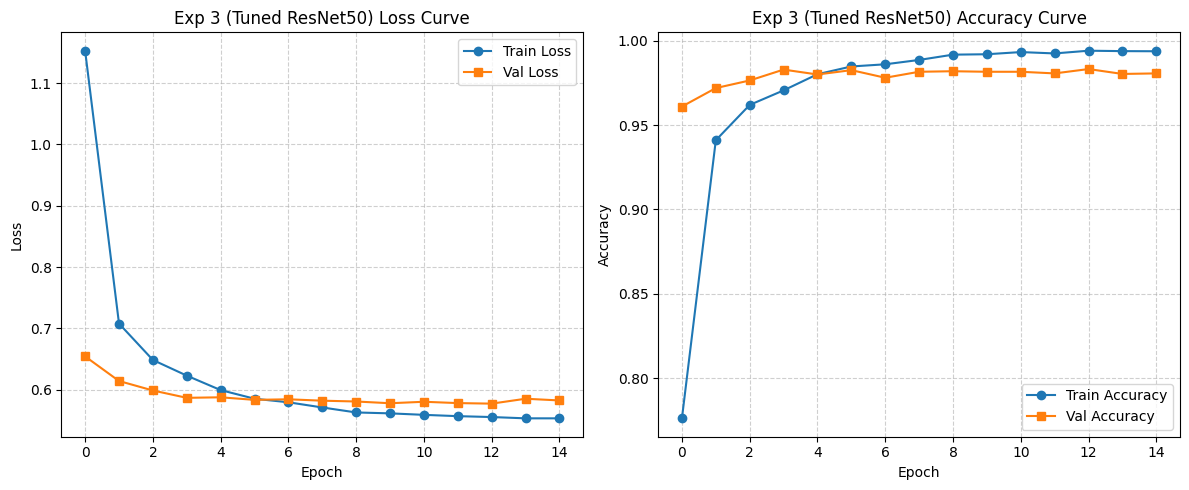

In [ ]:
# ==========================================
# Exp 3: Final Tuned ResNet50 (최종 최고 성능 모델)
# ==========================================
torch.manual_seed(42)

train_transform_exp3 = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_data, val_data = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(TransformDataset(train_data, train_transform_exp3), batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(TransformDataset(val_data, val_transform), batch_size=32, shuffle=False, num_workers=2)

model_exp3 = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model_exp3.fc = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(model_exp3.fc.in_features, num_classes)
)
model_exp3 = model_exp3.to(device)

criterion_exp3 = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_exp3 = optim.AdamW(model_exp3.parameters(), lr=5e-5, weight_decay=1e-4)
scheduler_exp3 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_exp3, mode='min', factor=0.5, patience=2)

history_exp3 = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_acc_exp3 = 0.0

for epoch in range(15):
    model_exp3.train()
    tr_loss, tr_corr, tr_tot = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer_exp3.zero_grad()
        outputs = model_exp3(images)
        loss = criterion_exp3(outputs, labels)
        loss.backward()
        optimizer_exp3.step()
        tr_loss += loss.item() * images.size(0)
        tr_tot += labels.size(0)
        tr_corr += (outputs.argmax(1) == labels).sum().item()

    model_exp3.eval()
    va_loss, va_corr, va_tot = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_exp3(images)
            loss = criterion_exp3(outputs, labels)
            va_loss += loss.item() * images.size(0)
            va_tot += labels.size(0)
            va_corr += (outputs.argmax(1) == labels).sum().item()

    ep_tr_loss, ep_tr_acc = tr_loss / tr_tot, tr_corr / tr_tot
    ep_va_loss, ep_va_acc = va_loss / va_tot, va_corr / va_tot
    scheduler_exp3.step(ep_va_loss)

    history_exp3["train_loss"].append(ep_tr_loss)
    history_exp3["val_loss"].append(ep_va_loss)
    history_exp3["train_acc"].append(ep_tr_acc)
    history_exp3["val_acc"].append(ep_va_acc)

    print(f"[Exp 3] Epoch [{epoch+1:02d}/15] Train Loss: {ep_tr_loss:.4f}, Acc: {ep_tr_acc:.4f} | Val Loss: {ep_va_loss:.4f}, Acc: {ep_va_acc:.4f}")
    if ep_va_acc > best_acc_exp3:
        best_acc_exp3 = ep_va_acc
        torch.save(model_exp3.state_dict(), "best_model_exp3.pth")

print(f"\n[Exp 3: Tuned ResNet50] 최고 검증 정확도: {best_acc_exp3:.4f}")

# TTA(Test-Time Augmentation) 최종 정확도 측정
model_exp3.load_state_dict(torch.load("best_model_exp3.pth"))
model_exp3.eval()
tta_corr, tta_tot = 0, 0

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        out_orig = torch.softmax(model_exp3(images), dim=1)
        out_flip = torch.softmax(model_exp3(torch.flip(images, dims=[3])), dim=1)
        avg_out = (out_orig + out_flip) / 2.0
        tta_tot += labels.size(0)
        tta_corr += (avg_out.argmax(1) == labels).sum().item()

print(f"[Exp 3 + TTA] 최종 검증 정확도: {tta_corr / tta_tot:.4f}")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_exp3["train_loss"], label="Train Loss", marker='o')
plt.plot(history_exp3["val_loss"], label="Val Loss", marker='s')
plt.title("Exp 3 (Tuned ResNet50) Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_exp3["train_acc"], label="Train Accuracy", marker='o')
plt.plot(history_exp3["val_acc"], label="Val Accuracy", marker='s')
plt.title("Exp 3 (Tuned ResNet50) Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("learning_curve_exp3.png", dpi=300)
plt.show()

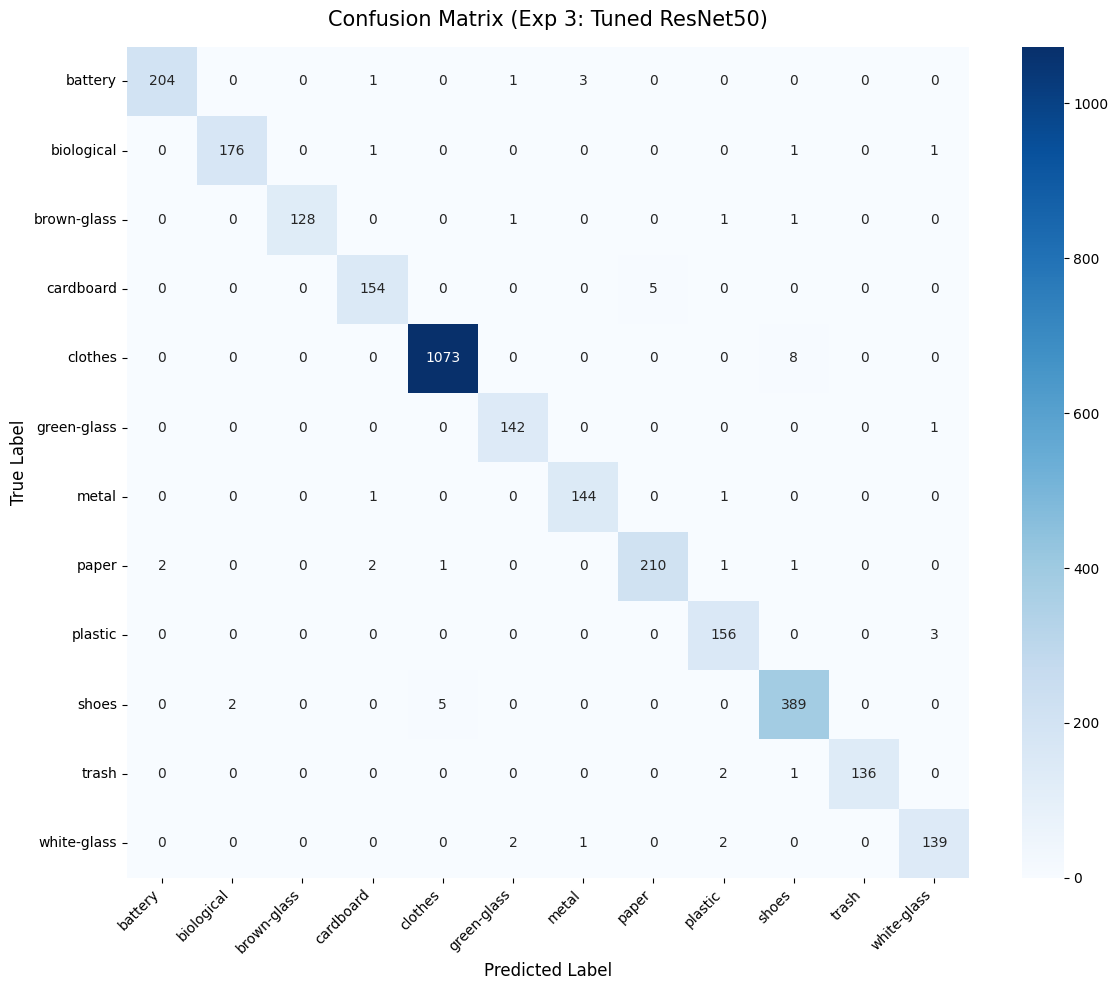


[클래스별 상세 분류 성능 리포트]
              precision    recall  f1-score   support

     battery     0.9903    0.9761    0.9831       209
  biological     0.9888    0.9832    0.9860       179
 brown-glass     1.0000    0.9771    0.9884       131
   cardboard     0.9686    0.9686    0.9686       159
     clothes     0.9944    0.9926    0.9935      1081
 green-glass     0.9726    0.9930    0.9827       143
       metal     0.9730    0.9863    0.9796       146
       paper     0.9767    0.9677    0.9722       217
     plastic     0.9571    0.9811    0.9689       159
       shoes     0.9701    0.9823    0.9762       396
       trash     1.0000    0.9784    0.9891       139
 white-glass     0.9653    0.9653    0.9653       144

    accuracy                         0.9832      3103
   macro avg     0.9797    0.9793    0.9795      3103
weighted avg     0.9834    0.9832    0.9833      3103



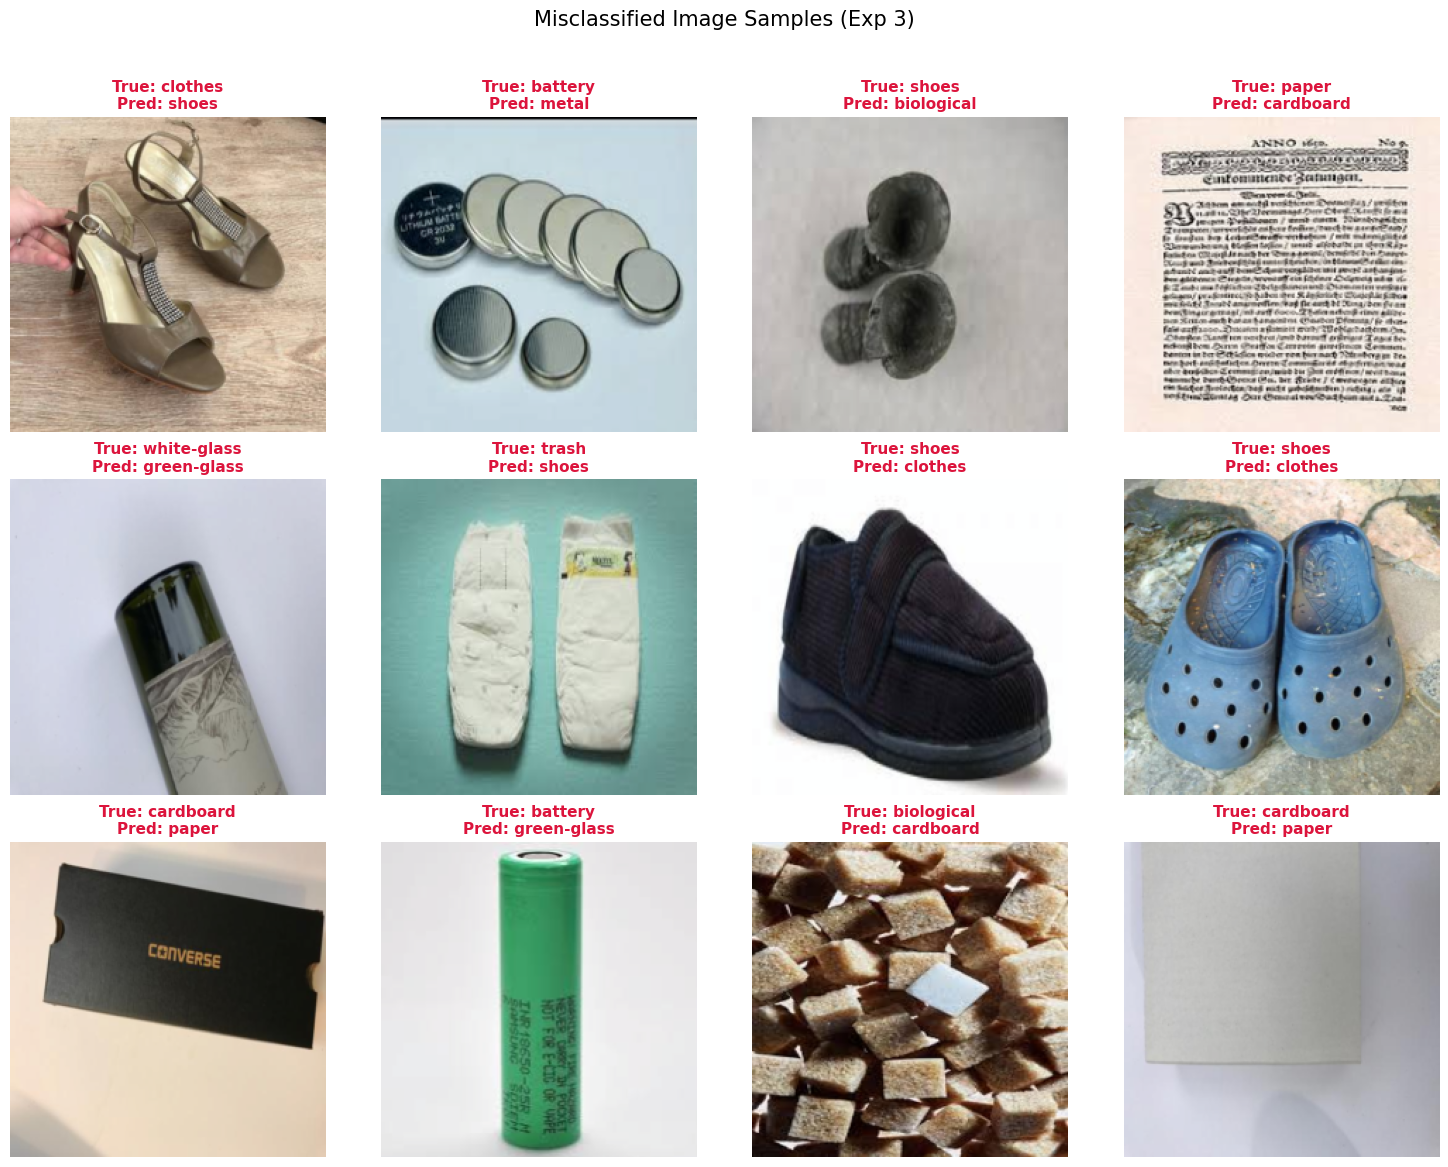

In [ ]:
# ==========================================
# 최종 모델(Exp 3) 오류 분석 및 시각화
# ==========================================
model_exp3.load_state_dict(torch.load("best_model_exp3.pth", map_location=device))
model_exp3.eval()

all_preds, all_labels = [], []
misclassified_images, misclassified_true, misclassified_pred = [], [], []
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model_exp3(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        if len(misclassified_images) < 12:
            wrong_mask = (preds != labels)
            w_imgs = images[wrong_mask].cpu()
            w_true = labels[wrong_mask].cpu()
            w_pred = preds[wrong_mask].cpu()

            for img, t, p in zip(w_imgs, w_true, w_pred):
                if len(misclassified_images) < 12:
                    img_np = np.clip(std * img.permute(1, 2, 0).numpy() + mean, 0, 1)
                    misclassified_images.append(img_np)
                    misclassified_true.append(full_dataset.classes[t.item()])
                    misclassified_pred.append(full_dataset.classes[p.item()])

class_names = full_dataset.classes

# 1. 혼동 행렬 시각화
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix (Exp 3: Tuned ResNet50)", fontsize=15, pad=15)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

# 2. 클래스별 상세 성적표 출력
print("\n[클래스별 상세 분류 성능 리포트]")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# 3. 오분류 이미지 시각화
num_wrong = len(misclassified_images)
if num_wrong > 0:
    cols = 4
    rows = (num_wrong + cols - 1) // cols
    plt.figure(figsize=(15, 3.8 * rows))
    for idx in range(num_wrong):
        plt.subplot(rows, cols, idx + 1)
        plt.imshow(misclassified_images[idx])
        plt.title(
            f"True: {misclassified_true[idx]}\nPred: {misclassified_pred[idx]}",
            color='crimson',
            fontsize=11,
            fontweight='bold'
        )
        plt.axis('off')
    plt.suptitle("Misclassified Image Samples (Exp 3)", fontsize=15, y=1.02)
    plt.tight_layout()
    plt.savefig("misclassified_samples.png", dpi=300, bbox_inches='tight')
    plt.show()

In [6]:
import os
import gdown
import torch
import torch.nn as nn
from torchvision import transforms, models
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files

# ==========================================================
# 1. 환경 및 클래스 이름 설정 (학습 셀을 안 돌렸어도 단독 실행 가능)
# ==========================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASS_NAMES = [
    'battery', 'biological', 'brown-glass', 'cardboard',
    'clothes', 'green-glass', 'metal', 'paper',
    'plastic', 'shoes', 'trash', 'white-glass'
]

# ==========================================================
# 2. 학습된 최고 성능 모델(Exp 3: ResNet50) 가중치 로드
# ==========================================================
model_path = "best_model_exp3.pth"
MODEL_FILE_ID = "여기에_best_model_exp3_pth_파일_ID를_붙여넣으세요"  # 구글 드라이브 공유 ID

if not os.path.exists(model_path):
    print("사전 학습된 모델 가중치(best_model_exp3.pth) 다운로드 중...")
    gdown.download(f"https://drive.google.com/uc?id={MODEL_FILE_ID}", model_path, quiet=False)

model_infer = models.resnet50(weights=None)
model_infer.fc = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(model_infer.fc.in_features, len(CLASS_NAMES))
)
model_infer.load_state_dict(torch.load(model_path, map_location=device))
model_infer = model_infer.to(device)
model_infer.eval()

# ==========================================================
# 3. 테스트 이미지 업로드 및 추론 함수
# ==========================================================
infer_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def predict_custom_image(image_path):
    img = Image.open(image_path).convert("RGB")
    input_tensor = infer_transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        # 원본 + 좌우반전 TTA 적용으로 예측 정확도 극대화
        out_orig = torch.softmax(model_infer(input_tensor), dim=1)
        out_flip = torch.softmax(model_infer(torch.flip(input_tensor, dims=[3])), dim=1)
        probs = ((out_orig + out_flip) / 2.0)[0]

    top3_prob, top3_idx = torch.topk(probs, 3)

    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.axis("off")
    title_text = (
        f"1st: {CLASS_NAMES[top3_idx[0]]} ({top3_prob[0]*100:.2f}%)\n"
        f"2nd: {CLASS_NAMES[top3_idx[1]]} ({top3_prob[1]*100:.2f}%) | "
        f"3rd: {CLASS_NAMES[top3_idx[2]]} ({top3_prob[2]*100:.2f}%)"
    )
    plt.title(title_text, fontsize=13, fontweight="bold", pad=12)
    plt.show()

# ==========================================================
# 4. 실행 시 파일 선택 창 팝업 -> 이미지 선택 즉시 결과 출력
# ==========================================================
print("분류할 테스트 이미지 파일을 선택해 주세요 (여러 장 동시 선택 가능):")
uploaded = files.upload()

for filename in uploaded.keys():
    predict_custom_image(filename)

사전 학습된 모델 가중치(best_model_exp3.pth) 다운로드 중...


FileURLRetrievalError: Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to change
	the permission to 'Anyone with the link', or have had many accesses.
	Check FAQ in https://github.com/wkentaro/gdown?tab=readme-ov-file#faq.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=여기에_best_model_exp3_pth_파일_ID를_붙여넣으세요

but Gdown can't. Please check connections and permissions.

In [ ]:
import os
import zipfile
import gdown
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# ==========================================================
# 1. 데이터셋 다운로드 및 준비
# ==========================================================
FILE_ID = "1TnN1s5xiyXSZkxMnYw9Ura4SQvUiUE6F"
zip_path = "/content/archive.zip"
extract_path = "/content/dataset"

if not os.path.exists(extract_path):
    if not os.path.exists(zip_path):
        gdown.download(f"https://drive.google.com/uc?id={FILE_ID}", zip_path, quiet=False)
    os.makedirs(extract_path, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

data_dir = next(root for root, dirs, files in os.walk(extract_path) if len(dirs) >= 10)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

full_dataset = datasets.ImageFolder(root=data_dir)
CLASSES = full_dataset.classes
IMG_SIZE = 224

# ==========================================================
# 2. 순수 torch.nn 기반 고성능 커스텀 CNN 정의
# ==========================================================
class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
        )
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.conv(x) + self.shortcut(x))


class GarbageCNN(nn.Module):
    def __init__(self, num_classes=12):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )
        self.stage1 = nn.Sequential(ResidualBlock(64, 64, 1), ResidualBlock(64, 64, 1))
        self.stage2 = nn.Sequential(ResidualBlock(64, 128, 2), ResidualBlock(128, 128, 1))
        self.stage3 = nn.Sequential(ResidualBlock(128, 256, 2), ResidualBlock(256, 256, 1))
        self.stage4 = nn.Sequential(ResidualBlock(256, 512, 2), ResidualBlock(512, 512, 1))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        return self.classifier(self.pool(x))


# ==========================================================
# 3. 데이터 분할 및 전처리 (검증/테스트용 전처리 일치 필수)
# ==========================================================
torch.manual_seed(42)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_data, val_data = random_split(full_dataset, [train_size, val_size])

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class TransformDataset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform
    def __getitem__(self, idx):
        x, y = self.subset[idx]
        return self.transform(x), y
    def __len__(self):
        return len(self.subset)

train_loader = DataLoader(TransformDataset(train_data, train_transform), batch_size=64, shuffle=True, num_workers=2)
val_loader = DataLoader(TransformDataset(val_data, val_transform), batch_size=64, shuffle=False, num_workers=2)

# ==========================================================
# 4. 모델 학습 (사전학습 가중치가 없으므로 35 Epoch 학습 권장)
# ==========================================================
EPOCHS = 35
model = GarbageCNN(num_classes=len(CLASSES)).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

best_acc = 0.0
for epoch in range(EPOCHS):
    model.train()
    tr_loss, tr_corr, tr_tot = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * imgs.size(0)
        tr_tot += labels.size(0)
        tr_corr += (out.argmax(1) == labels).sum().item()

    model.eval()
    va_loss, va_corr, va_tot = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            out = model(imgs)
            loss = criterion(out, labels)
            va_loss += loss.item() * imgs.size(0)
            va_tot += labels.size(0)
            va_corr += (out.argmax(1) == labels).sum().item()

    scheduler.step()
    va_acc = va_corr / va_tot
    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] Train Acc: {tr_corr/tr_tot:.4f} | Val Loss: {va_loss/va_tot:.4f}, Val Acc: {va_acc:.4f}")

    if va_acc > best_acc:
        best_acc = va_acc
        torch.save(model.state_dict(), "weights.pt")

print(f"\n학습 완료! 최고 검증 정확도: {best_acc:.4f} -> weights.pt 저장 완료")

In [ ]:
%%writefile model.py
import torch
from torch import nn
from torchvision import transforms

CLASSES = [
    "battery", "biological", "brown-glass", "cardboard", "clothes", "green-glass",
    "metal", "paper", "plastic", "shoes", "trash", "white-glass",
]

IMG_SIZE = 224


class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
        )
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.conv(x) + self.shortcut(x))


class GarbageCNN(nn.Module):
    def __init__(self, num_classes=12):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )
        self.stage1 = nn.Sequential(ResidualBlock(64, 64, 1), ResidualBlock(64, 64, 1))
        self.stage2 = nn.Sequential(ResidualBlock(64, 128, 2), ResidualBlock(128, 128, 1))
        self.stage3 = nn.Sequential(ResidualBlock(128, 256, 2), ResidualBlock(256, 256, 1))
        self.stage4 = nn.Sequential(ResidualBlock(256, 512, 2), ResidualBlock(512, 512, 1))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        return self.classifier(self.pool(x))


def load_model(weights_path, device):
    model = GarbageCNN(num_classes=len(CLASSES))
    state = torch.load(weights_path, map_location=device, weights_only=True)
    state = {k.removeprefix("module."): v for k, v in state.items()}
    model.load_state_dict(state)
    return model


def get_transform():
    return transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])

In [ ]:
import importlib.util, torch
from PIL import Image

spec = importlib.util.spec_from_file_location("m", "model.py")
m = importlib.util.module_from_spec(spec)
spec.loader.exec_module(m)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net = m.load_model("weights.pt", device).to(device).eval()

dummy_img = Image.new("RGB", (300, 300))
x = m.get_transform()(dummy_img).unsqueeze(0).to(device)
with torch.no_grad():
    out = net(x)
    print("출력 모양:", out.shape)  # torch.Size([1, 12]) 확인